# Health-guided train/skip at a matched update budget

**Complete** · 12/12 arms complete. Updated 2026-11-24T21:08:09+01:00.

## No-replay timing comparison

The registered Phase 1.2.5 correlated walk ends at 53,903 arrivals. Each policy
starts from the same seed-specific 8,000-arrival checkpoint. Every training
action updates on the current image alone at 0.25× the base learning rate,
with the same AdamW settings and deterministically paired masks.

| Policy | Post-calibration updates | Skips |
| --- | ---: | ---: |
| Health-selected | 18,648 | 27,255 |
| Periodic | 18,648 | 27,255 |
| Random | 18,648 | 27,255 |
| Always train | 45,903 | 0 |

The equal-budget policies match a 13/32 cumulative quota at every 512-arrival
block boundary. Periodic distributes updates evenly; random samples positions uniformly within
each block. Health-selected ranks the current image using the archived frozen +1 O3 Lasso.
It applies a causal quantile of the last 512 scores, adjusted for the
remaining block quota. The policy forces the last decisions when the quota otherwise cannot be met.
The feature monitor observes skipped images and supplies no replay to the optimizer.

New and historical reconstruction loss and native RankMe are measured on capture-disjoint
external banks with 256 images per bank and regime. A frozen
calibration encoder matches these banks to the incoming and preceding portions of the walk.
The same banks and masks are used by all four arms. Banks are evaluation-only. Time averages
integrate within each regime, with separate measurements at bank switches.

At the registered Phase 1.2 readouts, the same frozen-encoder linear probe recipe scores scene,
weather, lighting, traffic lights and pedestrians. The plotted mean gives each task equal weight.
Earlier points are recovered by replaying the saved train/skip actions with the original masks
and verifying the reconstructed learner against the archived loss and RankMe measurements.

Live time includes image preparation, controller measurements, optimizer steps and monitor
maintenance. Held-out health and probe evaluation times are reported separately.

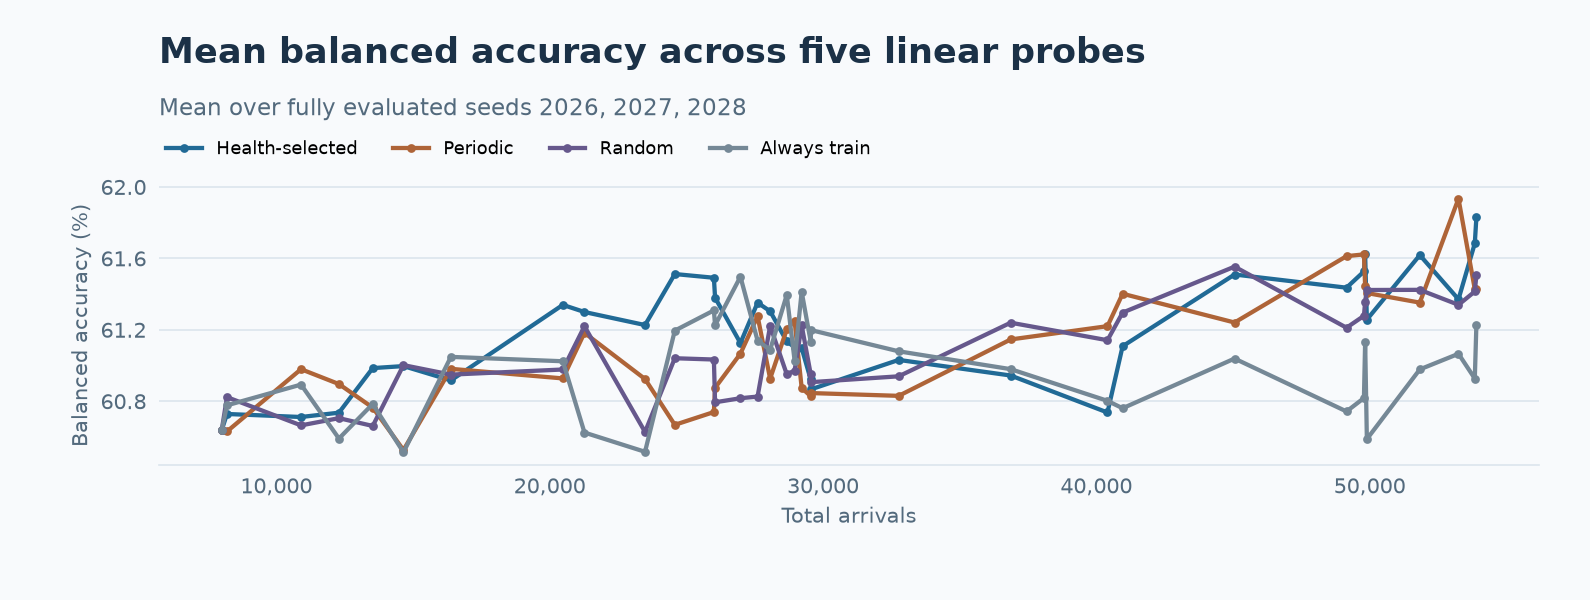

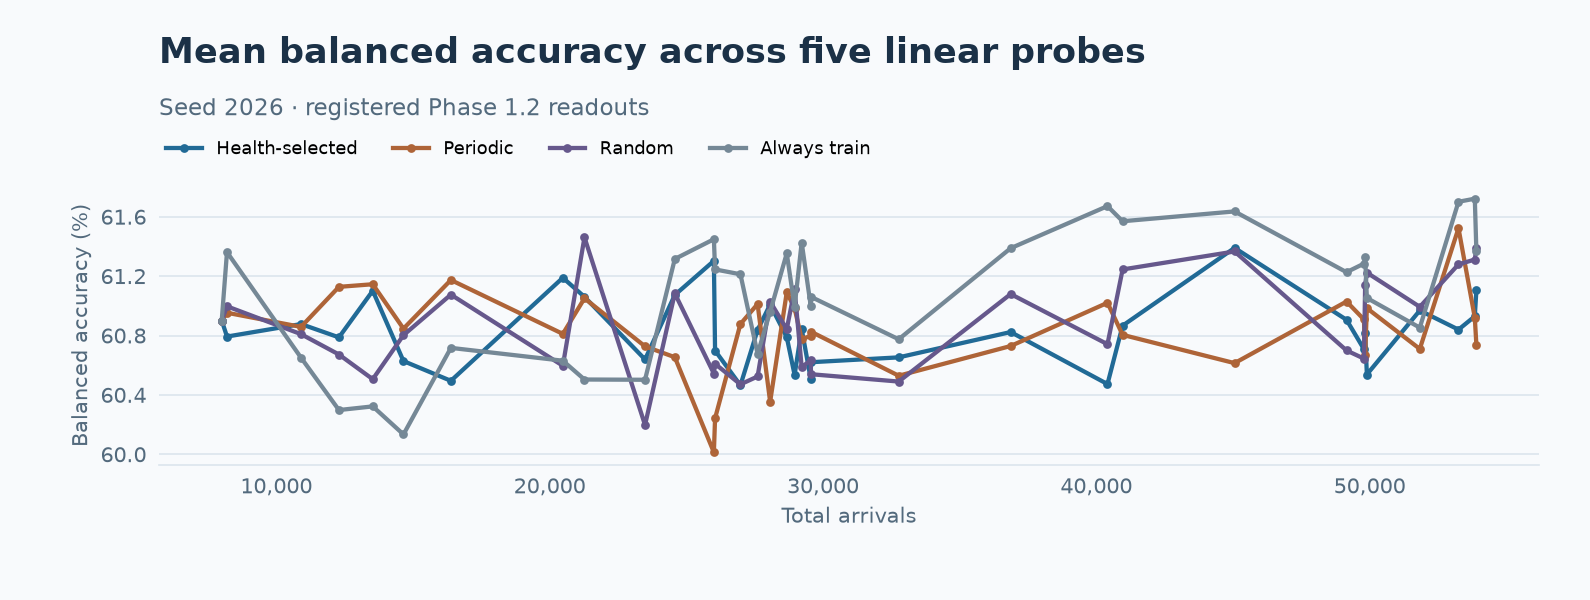

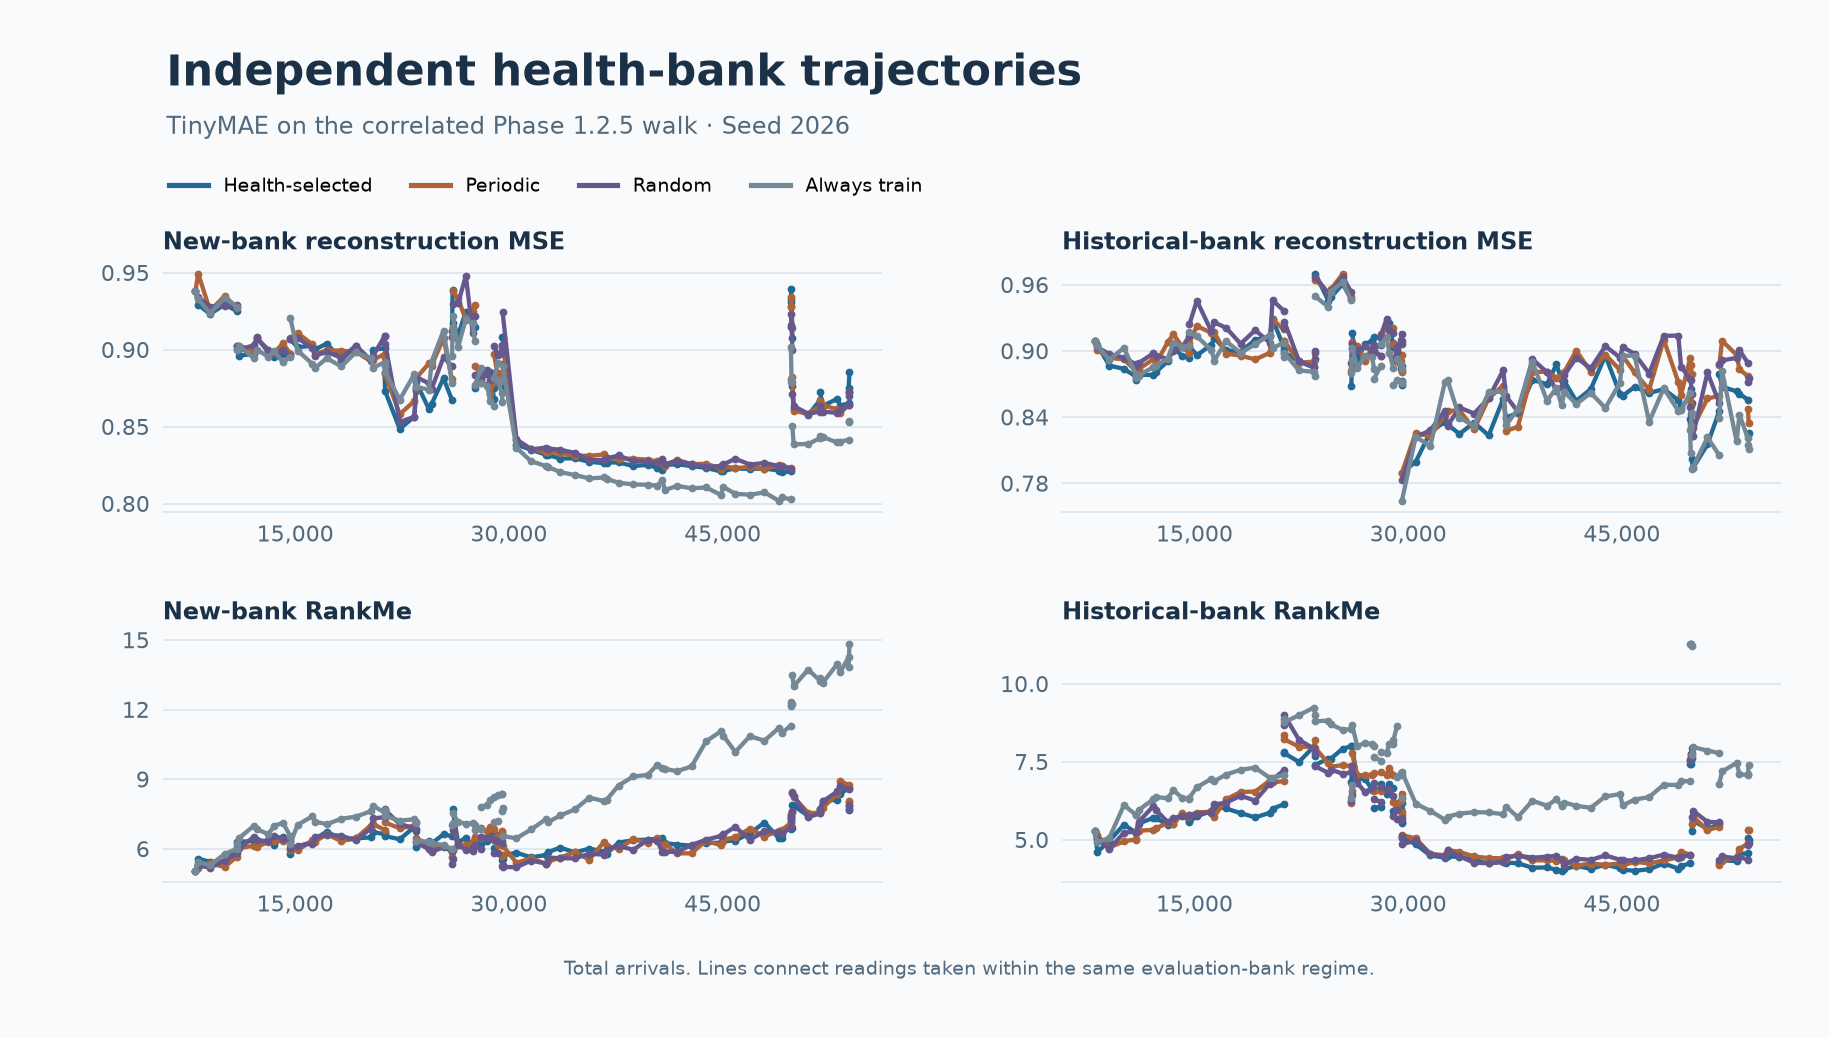

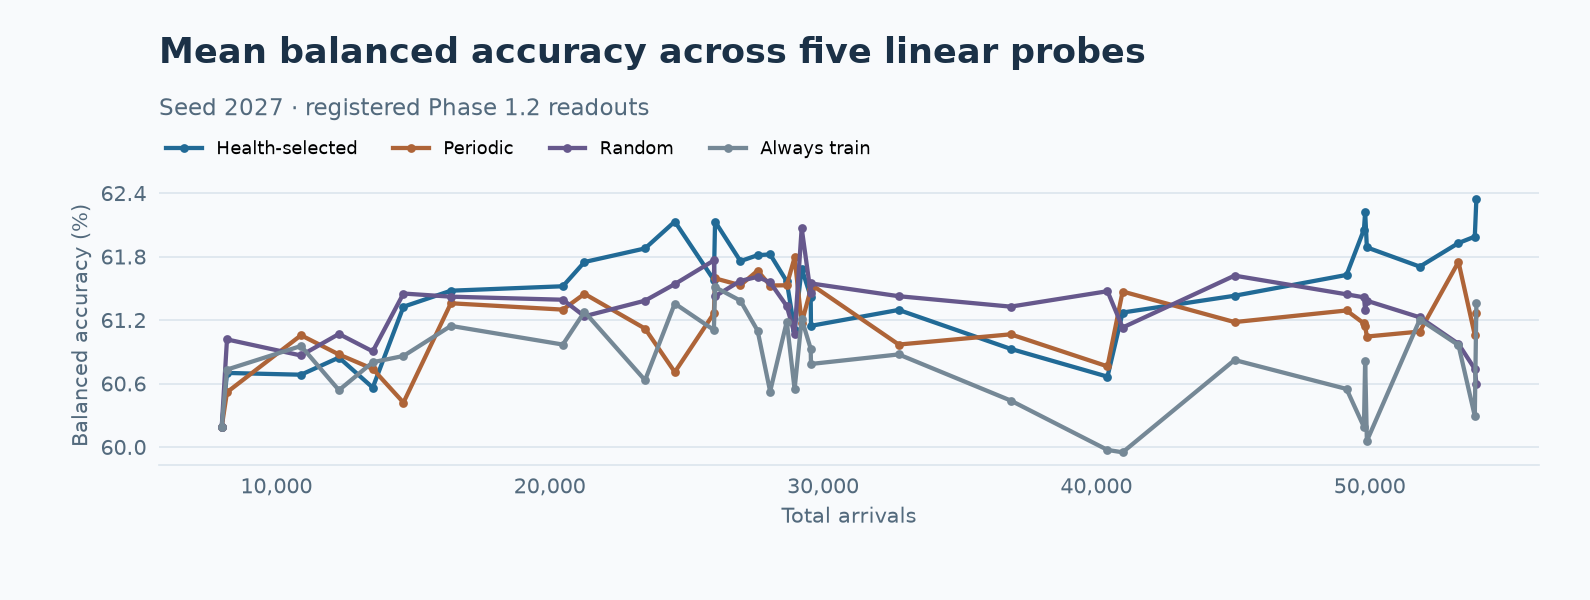

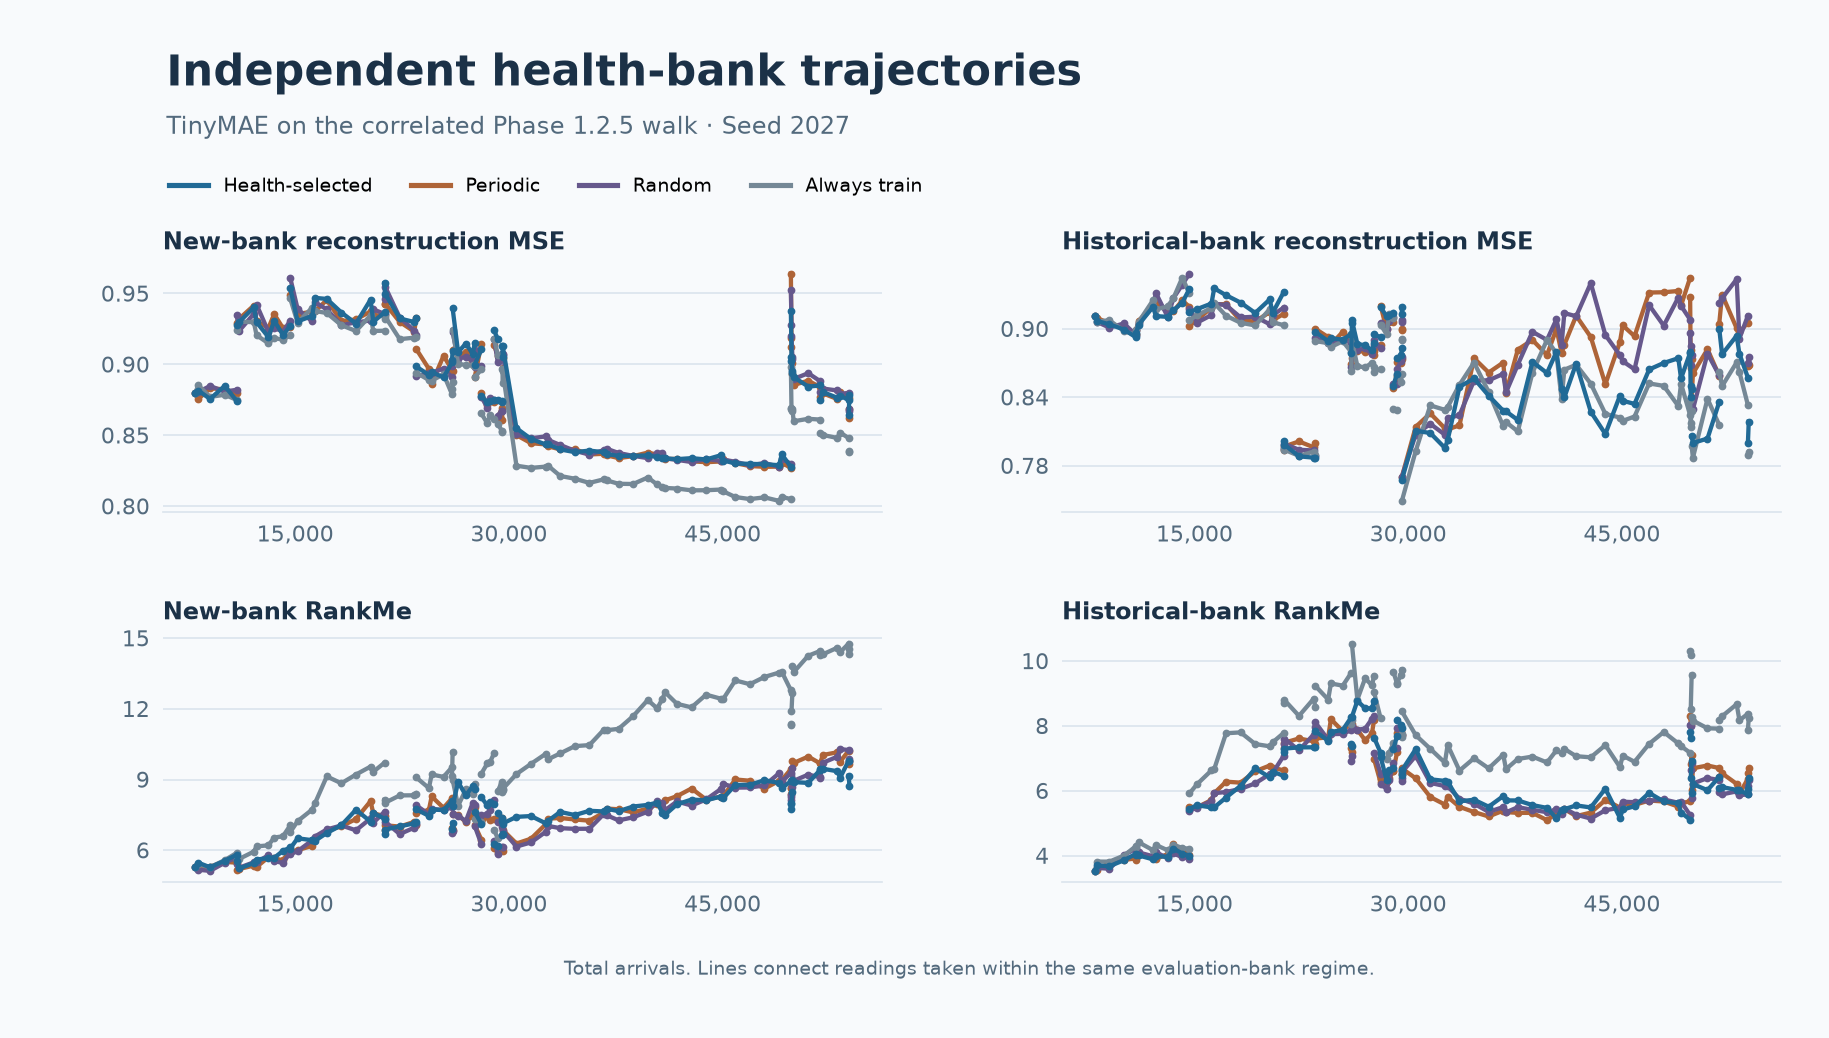

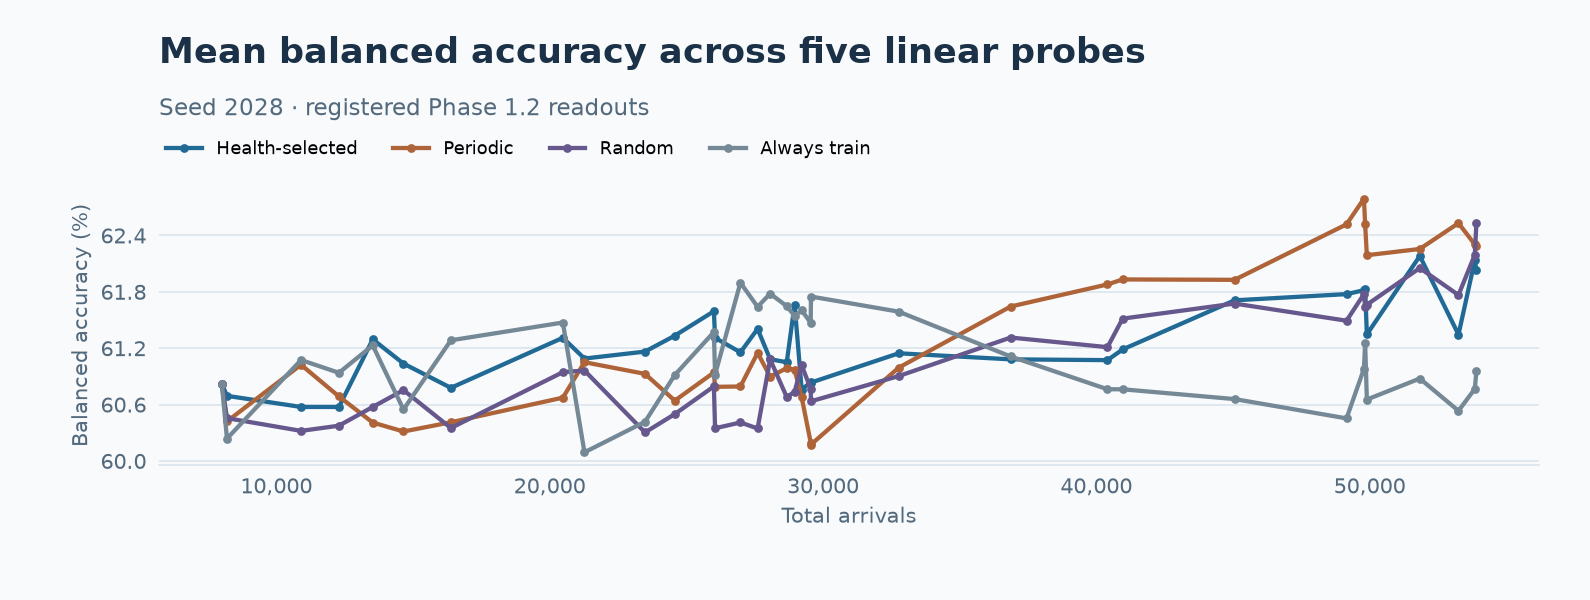

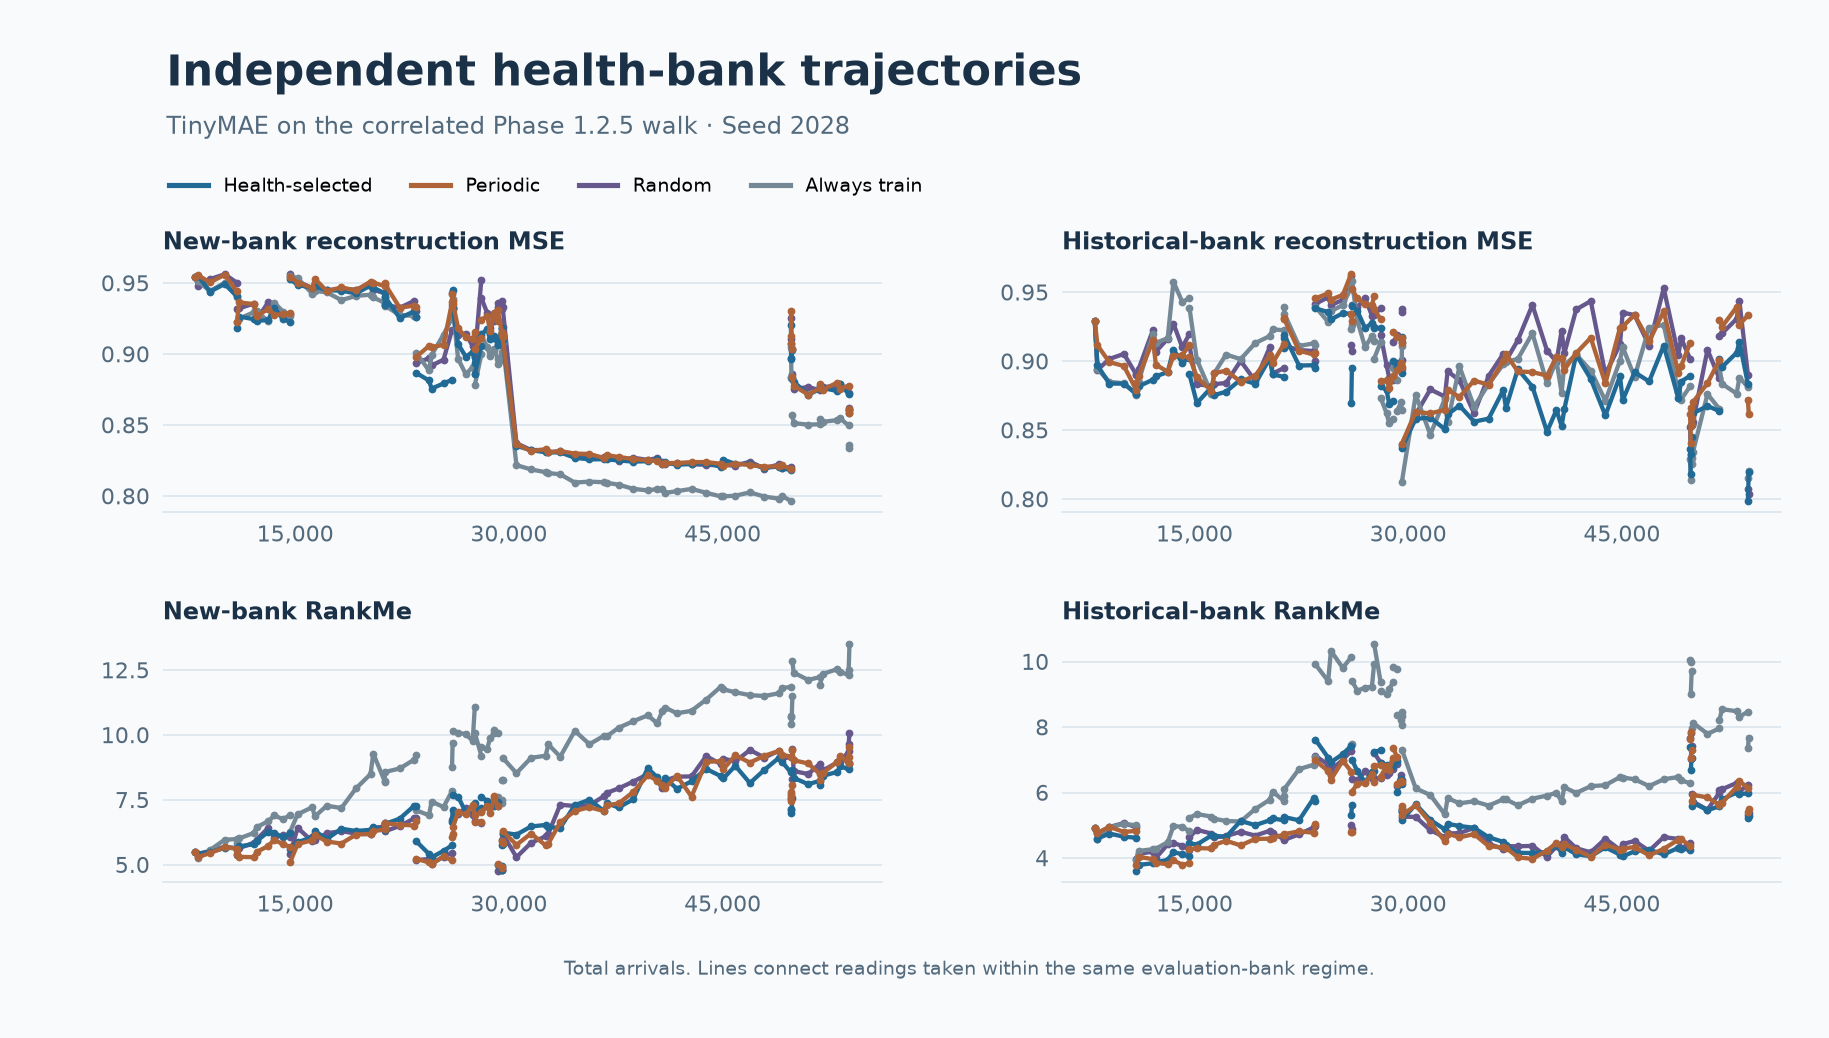

## Completed arms and actual runtime

| Seed | Policy | Updates | Live seconds | Controller and monitor seconds | Health readout seconds | Linear probe seconds | Quota-forced updates / skips |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026 | Health-selected | 18,648 | 772.0 | 595.8 | 3.4 | 8.6 | 113 / 219 |
| 2026 | Periodic | 18,648 | 162.0 | 0.0 | 3.4 | 8.7 | 0 / 0 |
| 2026 | Random | 18,648 | 162.4 | 0.0 | 3.3 | 8.7 | 0 / 0 |
| 2026 | Always train | 45,903 | 425.6 | 0.1 | 3.3 | 8.4 | 0 / 0 |
| 2027 | Periodic | 18,648 | 171.3 | 0.0 | 3.3 | 8.3 | 0 / 0 |
| 2027 | Random | 18,648 | 170.9 | 0.0 | 3.2 | 8.5 | 0 / 0 |
| 2027 | Always train | 45,903 | 414.3 | 0.1 | 3.4 | 8.3 | 0 / 0 |
| 2027 | Health-selected | 18,648 | 785.7 | 611.7 | 3.6 | 8.5 | 357 / 313 |
| 2028 | Random | 18,648 | 166.3 | 0.0 | 3.6 | 8.2 | 0 / 0 |
| 2028 | Always train | 45,903 | 404.9 | 0.1 | 3.5 | 8.3 | 0 / 0 |
| 2028 | Health-selected | 18,648 | 795.6 | 620.0 | 3.5 | 8.4 | 165 / 272 |
| 2028 | Periodic | 18,648 | 163.8 | 0.0 | 4.0 | 8.3 | 0 / 0 |

## Time-averaged readouts

| Seed | Policy | New-bank reconstruction MSE | Historical-bank reconstruction MSE | New-bank RankMe | Historical-bank RankMe | Mean linear probe (%) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| 2026 | Health-selected | 0.8629 | 0.8751 | 6.4045 | 5.2623 | 60.8512 |
| 2026 | Periodic | 0.8665 | 0.8852 | 6.3672 | 5.4165 | 60.8338 |
| 2026 | Random | 0.8666 | 0.8912 | 6.3553 | 5.4187 | 60.8827 |
| 2026 | Always train | 0.8564 | 0.8741 | 8.4206 | 6.8048 | 61.0459 |
| 2027 | Periodic | 0.8783 | 0.8846 | 7.4718 | 5.8491 | 61.1418 |
| 2027 | Random | 0.8789 | 0.8842 | 7.3300 | 5.8492 | 61.3458 |
| 2027 | Always train | 0.8640 | 0.8630 | 10.0332 | 7.1275 | 60.7603 |
| 2027 | Health-selected | 0.8792 | 0.8668 | 7.5175 | 5.9217 | 61.3541 |
| 2028 | Random | 0.8824 | 0.9071 | 7.1528 | 4.9948 | 61.0115 |
| 2028 | Always train | 0.8688 | 0.8970 | 9.2830 | 6.4361 | 60.9889 |
| 2028 | Health-selected | 0.8785 | 0.8856 | 7.0745 | 4.9893 | 61.2142 |
| 2028 | Periodic | 0.8828 | 0.9022 | 7.0152 | 4.8750 | 61.2621 |

## Endpoint readouts

| Seed | Policy | New-bank reconstruction MSE | Historical-bank reconstruction MSE | New-bank RankMe | Historical-bank RankMe | Mean linear probe (%) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| 2026 | Health-selected | 0.8855 | 0.8257 | 7.6894 | 5.0094 | 61.1046 |
| 2026 | Periodic | 0.8724 | 0.8346 | 8.0345 | 5.3206 | 60.7359 |
| 2026 | Random | 0.8698 | 0.8759 | 7.7080 | 4.9017 | 61.3898 |
| 2026 | Always train | 0.8536 | 0.8113 | 14.8473 | 7.3932 | 61.3666 |
| 2027 | Periodic | 0.8683 | 0.8687 | 9.7948 | 6.6935 | 61.2626 |
| 2027 | Random | 0.8686 | 0.8751 | 9.8511 | 6.3427 | 60.5990 |
| 2027 | Always train | 0.8387 | 0.7921 | 14.5544 | 8.2355 | 61.3656 |
| 2027 | Health-selected | 0.8785 | 0.8187 | 8.7297 | 6.3941 | 62.3473 |
| 2028 | Random | 0.8619 | 0.8038 | 10.0731 | 5.3683 | 62.5279 |
| 2028 | Always train | 0.8359 | 0.8202 | 13.5229 | 7.6807 | 60.9536 |
| 2028 | Health-selected | 0.8586 | 0.8198 | 8.9363 | 5.3000 | 62.0364 |
| 2028 | Periodic | 0.8589 | 0.8620 | 9.5510 | 5.4967 | 62.2901 |

## Paired differences across 3 fully evaluated seeds

| Health-selected minus | Period | New MSE | Historical MSE | New RankMe | Historical RankMe | Mean probe (pp) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Periodic | Time average | -0.0023 [-0.0042, +0.0009] | -0.0148 [-0.0178, -0.0101] | +0.0475 [+0.0373, +0.0593] | +0.0109 [-0.1543, +0.1143] | +0.0606 [-0.0479, +0.2123] |
| Periodic | Endpoint | +0.0077 [-0.0002, +0.0131] | -0.0337 [-0.0499, -0.0089] | -0.6750 [-1.0651, -0.3451] | -0.2691 [-0.3112, -0.1967] | +0.3999 [-0.2537, +1.0847] |
| Random | Time average | -0.0024 [-0.0039, +0.0003] | -0.0183 [-0.0215, -0.0161] | +0.0528 [-0.0783, +0.1876] | -0.0298 [-0.1565, +0.0726] | +0.0599 [-0.0315, +0.2027] |
| Random | Endpoint | +0.0075 [-0.0033, +0.0157] | -0.0302 [-0.0564, +0.0159] | -0.7589 [-1.1368, -0.0187] | +0.0303 [-0.0683, +0.1077] | +0.3239 [-0.4915, +1.7483] |
| Always train | Time average | +0.0105 [+0.0065, +0.0152] | -0.0022 [-0.0114, +0.0038] | -2.2467 [-2.5156, -2.0161] | -1.3984 [-1.5426, -1.2058] | +0.2082 [-0.1947, +0.5938] |
| Always train | Endpoint | +0.0315 [+0.0227, +0.0399] | +0.0135 [-0.0004, +0.0266] | -5.8564 [-7.1579, -4.5867] | -2.2020 [-2.3838, -1.8414] | +0.6008 [-0.2620, +1.0828] |

Negative MSE and positive RankMe or probe differences favor health selection. Where shown, intervals resample seeds with paired policies kept together.

## Files

Reopen this notebook to view the latest saved snapshot. The [runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/run_train_skip_budget.py)
and [run records](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/matched-train-skip/full-walk/)
include the exact actions, timing stages, and readouts.